# SpaceSleepTwin — HERA quantitative benchmark (exploratory)
Notebook autossuficiente para Kaggle: numpy, pandas, scipy, matplotlib. Não requer dados pessoais nem Internet. Usa o motor do notebook simulacao_spacesleeptwin.ipynb, sem reajustar seus parâmetros.

**Objetivo:** comparar o contraste de fase DLS−SLS do oscilador com o contraste agregado publicado. Isto é um benchmark exploratório; não valida previsões individuais, latência, intervenções em voo ou um gêmeo digital completo.

## Dados publicados e hipóteses
Fonte: Rahman et al., J Pineal Res. 2022, DOI [10.1111/jpi.12826](https://doi.org/10.1111/jpi.12826), [texto e Tabela 1](https://pmc.ncbi.nlm.nih.gov/articles/PMC11316501/).
Sono: 23–07 h (duas noites), 02–07 h (cinco noites), repetidos. DLS reduz luz três horas antes de deitar. Janela de coleta: 48 h iniciadas nos dias 5,12,19,26,33,43.
Alvo agregado: acrofase urinária aMT6s SLS 6,22 h; DLS 4,76 h; contraste −1,46 h. Pré-missão: SLS 4,24 h; DLS 3,69 h: diferença entre mudanças −0,91 h, apenas descritiva.

Entradas verticais da Tabela 1:
| Cenário | SLS dia/tarde | DLS dia | DLS tarde |
|---|---:|---:|---:|
| L1 fotópico | 122 | 264 | 13 |
| L2 fotópico | 143 | 80 | 4 |
| L1 melEDI (proxy experimental) | 89 | 233 | 8 |

Lux fotópico é a entrada original. **melEDI não é intercambiável com lux fotópico**: a terceira linha testa apenas a sensibilidade de uma substituição ingênua; não representa um modelo espectral validado.

Hipóteses não observadas: permanência no mesmo nível durante vigília; ausência de luz nos olhos durante sono; 21 dias prévios em 150 lux e sono 23–07 h; mesma fase inicial entre grupos; primeiro ciclo começa com duas noites longas. Exploram-se todas as sete posições do ciclo e τ=23,8/24,2/24,6 h, sem selecionar a que mais se aproxima do alvo.

## Medida do modelo
Extrai mínimos de x e compara horários por diferenças circulares. Não usa atan2 diário como horário de pico de melatonina. x-min é um proxy circadiano; para vinculá-lo a aMT6s seria necessária uma relação entre marcadores validada. Um deslocamento fixo comum cancelaria no contraste, mas não podemos presumir que seja constante entre condições.

Referência do modelo: [Forger, Jewett & Kronauer (1999), A Simpler Model of the Human Circadian Pacemaker](https://doi.org/10.1177/074873099129000867).
Não é um modelo de secreção ou excreção de melatonina. Coletas urinárias reais foram ajustadas por cosinor; aqui se usa média circular dos mínimos nas janelas, não reanálise da urina.

## Interpretação
Resultado na direção esperada é consistência qualitativa. Proximidade numérica é concordância descritiva, não confirmação independente: alvo já conhecido, exposição individual desconhecida e marcadores diferentes. Não há critério de aprovação pós-hoc nem intervalos de confiança inventados. As médias publicadas vêm de modelo misto; nossa média das seis janelas não reproduz esse estimador.

A exposição noturna reduzida em dois estágios e a movimentação entre ambientes requerem o suplemento e registros individuais para uma reprodução mais fiel. O cenário L1 resume as três horas finais em 13 lux.

Separar prever de reduzir: previsão demanda avaliação em pessoas/noites futuras; redução exige comparação de intervenção. HERA é análogo terrestre. Dados individuais são disponibilizados mediante pedido ao LSDA segundo o artigo. Isso não prova ausência de qualquer outro conjunto público de astronautas.



In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from IPython.display import display
import sys, scipy
print("Python", sys.version.split()[0], "SciPy", scipy.__version__)
OBSERVED_DELTA = 4.76 - 6.22
SAMPLE_DAYS = [5,12,19,26,33,43]
# Table 1: eye-level vertical measurements. Photopic is native Forger99 input.
LIGHTS = {
 "L1_photopic": {"SLS": (122.,122.), "DLS": (264.,13.)},
 "L2_photopic": {"SLS": (143.,143.), "DLS": (80.,4.)},
 "L1_melEDI_proxy": {"SLS": (89.,89.), "DLS": (233.,8.)},
}
def derivative(t, y, tau, intensity):
    x, xc, n = y
    alpha = .05 * (intensity/9500.)**.5 if intensity > 0 else 0.
    B = 33.75*(1-n)*alpha*(1-.4*x)*(1-.4*xc)
    return [np.pi/12*(xc+B),
            np.pi/12*(.23*(xc-4*xc**3/3)-x*((24/(.99669*tau))**2+.55*B)),
            60*(alpha*(1-n)-.0075*n)]
def integrate_segment(start, end, state, tau, intensity, step):
    grid = np.linspace(start,end,int(np.ceil((end-start)/step))+1)
    sol = solve_ivp(lambda t,y: derivative(t,y,tau,intensity),(start,end),state,
                    t_eval=grid,rtol=1e-8,atol=1e-10,max_step=.25)
    assert sol.success, sol.message
    return sol.t, sol.y
def run(condition, tau=24.2, location="L1_photopic", cycle_offset=0, step=1/12):
    # Common premission equilibration is an assumption, not measured HERA exposure.
    state = np.array([1.,0.,.5])
    for day in range(-21,0):
        _, v = integrate_segment(day*24,day*24+16,state,tau,150.,step)
        _, w = integrate_segment(day*24+16,(day+1)*24,v[:,-1],tau,0.,step)
        state = w[:,-1]
    ts, xs = [], []
    for day in range(45):
        # t=0 is 07:00; two 8h nights followed by five 5h nights.
        awake = 16. if (day+cycle_offset)%7 < 2 else 19.
        daytime, evening = LIGHTS[location][condition]
        segments = [(0,awake-3,daytime),(awake-3,awake,evening),(awake,24,0.)]
        for start,end,I in segments:
            t,v=integrate_segment(day*24+start,day*24+end,state,tau,I,step)
            state=v[:,-1]; ts.extend(t[:-1]); xs.extend(v[0,:-1])
    ts=np.array(ts); xs=np.array(xs)
    # x minima: phase proxy, not predicted urinary melatonin concentrations.
    peaks,_=find_peaks(-xs,distance=int(18/step))
    times=[]
    for i in peaks:
        if i<1 or i>=len(xs)-1: continue
        a,b,c=xs[i-1:i+2]
        shift=.5*(a-c)/(a-2*b+c)
        times.append(ts[i]+np.clip(shift,-1,1)*(ts[i+1]-ts[i]))
    times=np.array(times)
    rows=[]
    for md in SAMPLE_DAYS:
        selected=times[(times >= (md-1)*24)&(times < (md+1)*24)]
        clock=(selected+7)%24
        # Circular mean avoids a midnight wrap.
        angle=np.mean(np.exp(2j*np.pi*clock/24))
        h=np.angle(angle)*24/(2*np.pi)%24
        rows.append({"mission_day":md,"phase_proxy_h":h,"minima_count":len(selected)})
    return pd.DataFrame(rows)
def circ_diff(a,b):
    return (a-b+12)%24-12
def compare(**kwargs):
    s=run("SLS",**kwargs); d=run("DLS",**kwargs)
    assert (s.minima_count > 0).all() and (d.minima_count > 0).all()
    out=s[["mission_day"]].copy()
    out["SLS_proxy_h"]=s.phase_proxy_h
    out["DLS_proxy_h"]=d.phase_proxy_h
    out["DLS_minus_SLS_h"]=circ_diff(d.phase_proxy_h,s.phase_proxy_h)
    return out
primary=compare()
display(primary.round(3))
delta=float(primary.DLS_minus_SLS_h.mean())
print(f"Primary proxy contrast: {delta:.3f} h; observed urinary contrast: {OBSERVED_DELTA:.3f} h")
print(f"Descriptive discrepancy: {abs(delta-OBSERVED_DELTA)*60:.1f} min (different markers)")



Python 3.12.14 SciPy 1.17.0
   mission_day  SLS_proxy_h  DLS_proxy_h  DLS_minus_SLS_h
0            5        5.577        4.557           -1.019
1           12        5.925        4.591           -1.334
2           19        5.991        4.596           -1.395
3           26        6.003        4.596           -1.407
4           33        6.005        4.596           -1.409
5           43        5.591        4.180           -1.410
Primary proxy contrast: -1.329 h; observed urinary contrast: -1.460 h
Descriptive discrepancy: 7.9 min (different markers)


            scenario  value  contrast_h
0       cycle_offset      0      -1.329
1       cycle_offset      1      -1.334
2       cycle_offset      2      -1.335
3       cycle_offset      3      -1.330
4       cycle_offset      4      -1.329
5       cycle_offset      5      -1.328
6       cycle_offset      6      -1.327
7   intrinsic_period   23.8      -0.690
8   intrinsic_period   24.6      -1.133
9        L2_photopic  input      -1.113
10   L1_melEDI_proxy  input      -1.433
5 versus 2.5 min output grid: maximum contrast difference = 0.0014 min
Identical-light control: zero contrast confirmed
Sensitivity ranges are scenarios, not confidence intervals.


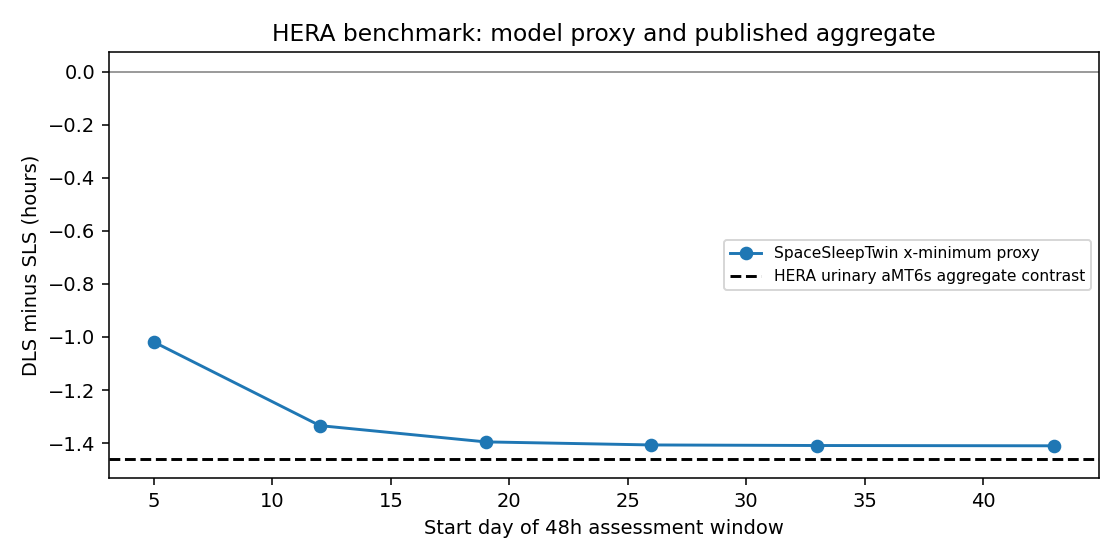

In [2]:
rows=[]
for offset in range(7):
    c=compare(cycle_offset=offset)
    rows.append(dict(scenario="cycle_offset",value=offset,contrast_h=c.DLS_minus_SLS_h.mean()))
for tau in [23.8,24.6]:
    c=compare(tau=tau)
    rows.append(dict(scenario="intrinsic_period",value=tau,contrast_h=c.DLS_minus_SLS_h.mean()))
for loc in ["L2_photopic","L1_melEDI_proxy"]:
    c=compare(location=loc)
    rows.append(dict(scenario=loc,value="input",contrast_h=c.DLS_minus_SLS_h.mean()))
sensitivity=pd.DataFrame(rows)
display(sensitivity.round(3))
fine=compare(step=1/24)
diff=np.max(np.abs(fine.DLS_minus_SLS_h-primary.DLS_minus_SLS_h))*60
print(f"5 versus 2.5 min output grid: maximum contrast difference = {diff:.4f} min")
assert diff < .5, "Inspect numerical convergence"
identical=LIGHTS["L1_photopic"]["DLS"]
try:
    LIGHTS["L1_photopic"]["DLS"]=LIGHTS["L1_photopic"]["SLS"]
    null=compare()
    assert np.max(np.abs(null.DLS_minus_SLS_h))<1e-8
finally:
    LIGHTS["L1_photopic"]["DLS"]=identical
print("Identical-light control: zero contrast confirmed")
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(primary.mission_day,primary.DLS_minus_SLS_h,"o-",label="SpaceSleepTwin x-minimum proxy")
ax.axhline(OBSERVED_DELTA,color="black",ls="--",label="HERA urinary aMT6s aggregate contrast")
ax.axhline(0,color="gray",lw=.8)
ax.set(xlabel="Start day of 48h assessment window",ylabel="DLS minus SLS (hours)",
       title="HERA benchmark: model proxy and published aggregate")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()
print("Sensitivity ranges are scenarios, not confidence intervals.")



## Resultado executado e conclusão
Contraste principal DLS−SLS: **−1,329 h**. Alvo agregado publicado: **−1,460 h**. Discrepância descritiva: **7,9 min**. Não ajustamos parâmetros para minimizar essa discrepância.

A posição do ciclo semanal produziu −1,335 a −1,327 h. Com τ=23,8 h, o contraste foi −0,690 h; com τ=24,6 h, −1,133 h. O cenário fotópico L2 produziu −1,113 h. O proxy melEDI produziu −1,433 h, mas não pode ser usado para escolher ou validar a entrada espectral. O resultado depende de hipóteses fisiológicas e de exposição; não inferimos acurácia individual a partir da proximidade entre médias.

Controle com luz idêntica: contraste zero. Refinamento da grade de saída de 5 para 2,5 minutos: diferença máxima de contraste 0,0014 min. Isto verifica implementação numérica, não validade biológica.

**Formulação defensável:** sob uma reconstrução simplificada da iluminação e do sono do HERA, o componente circadiano do SpaceSleepTwin reproduziu a direção e aproximou a magnitude do contraste agregado publicado. A comparação entre marcadores distintos permanece exploratória. Não demonstra benefício em astronautas nem valida previsão individual.

Próximos passos: auditar suplemento e exposição pessoal; estabelecer a relação entre x-min e acrofase aMT6s; obter dados individuais LSDA; fixar parâmetros e protocolo antes de testar outra missão/coorte. Os valores agregados já conhecidos não constituem conjunto reservado.

Execução: células rodadas sequencialmente em Python 3.12.14/SciPy 1.17.0; dependências científicas disponíveis no Kaggle. A publicação e execução dentro da conta Kaggle não foram feitas.
